# Project 3: Tsunami
In this project, we will use Dedalus to model the propagation of Tsunami waves. Tsunami typically have wavelengths larger than 100km and periods of about 1 hour. Since their wavelength is much larger than the depth of the ocean, Tsunami can be modelled using the shallow water equations.

Here, we will use Dedalus to solve an initial value problem for the shallow water equations. We will generate a Tsunami using a localized disturbance to the water height.

Student tasks are in [Section 1.3]( #section1pt3 ), [Section 2.3]( #section2pt3 ), and [Section 3.3]( #section3pt3 ).

## Setup
If you are using Google colab, run the script below to install Dedalus

In [1]:
# Set environment variables for best performance
%env OMP_NUM_THREADS=1
%env NUMEXPR_MAX_THREADS=1

# Minimize logging output
import logging
logging.disable(logging.DEBUG)

# Check if running on google colab
import os
using_google_colab = bool(os.getenv("COLAB_RELEASE_TAG"))

# Check for Dedalus
try:
    import dedalus.public as de
    print("Dedalus already installed :)")
except:
    print("Dedalus not installed yet.")
    if using_google_colab:
        print("Installing for Google Colab.")
        print()
        # Step 1: Install FFTW
        !apt-get install libfftw3-dev
        !apt-get install libfftw3-mpi-dev
        # Step 2: Set paths for Dedalus installation
        import os
        os.environ['MPI_INCLUDE_PATH'] = "/usr/lib/x86_64-linux-gnu/openmpi/include"
        os.environ['MPI_LIBRARY_PATH'] = "/usr/lib/x86_64-linux-gnu"
        os.environ['FFTW_INCLUDE_PATH'] = "/usr/include"
        os.environ['FFTW_LIBRARY_PATH'] = "/usr/lib/x86_64-linux-gnu"
        # Step 3: Install Dedalus using pip
        !pip3 install cython mpi4py numpy setuptools wheel
        !CC=mpicc pip3 install --no-cache --no-build-isolation http://github.com/dedalusproject/dedalus/zipball/master/
        !pip3 install -q ipympl
        # Step 4: Check installation
        print()
        try:
            import dedalus.public as de
            print("Dedalus successfully installed :)")
        except:
            print("Error installing Dedalus :(")
            raise
    else:
        print("See website for installation instructions:")
        print("https://dedalus-project.readthedocs.io/en/latest/pages/installation.html")

# Setup interactive matplotlib
if using_google_colab:
    from google.colab import output
    output.enable_custom_widget_manager()

env: OMP_NUM_THREADS=1
env: NUMEXPR_MAX_THREADS=1
Dedalus not installed yet.
Installing for Google Colab.

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libfftw3-bin libfftw3-long3 libfftw3-quad3 libfftw3-single3
Suggested packages:
  libfftw3-doc
The following NEW packages will be installed:
  libfftw3-bin libfftw3-dev libfftw3-long3 libfftw3-quad3 libfftw3-single3
0 upgraded, 5 newly installed, 0 to remove and 0 not upgraded.
Need to get 4,312 kB of archives.
After this operation, 22.3 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/main amd64 libfftw3-long3 amd64 3.3.10-1ubuntu3 [374 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble/main amd64 libfftw3-quad3 amd64 3.3.10-1ubuntu3 [658 kB]
Get:3 http://archive.ubuntu.com/ubuntu noble/main amd64 libfftw3-single3 amd64 3.3.10-1ubuntu3 [868 kB]
Get:4 http://archive.ubuntu.com/ubuntu noble/main a

## 1.  1D shallow water equations
Let's start by solving the shallow water equations in 1D with periodic boundary conditions in our spatial variable, $x$. The script below solves the following equations:

$$ \partial_t u + g \partial_x(h) = - u\partial_x u$$
$$ \partial_t h + \partial_x(Hu) = -\partial_x(hu)$$

In these equations, $g$ is the constant gravitational acceleration, $u$ is the velocity in the $x$ direction, $H$ is the resting height, and $h$ is the height of the free surface relative to $H$. Note that the terms on the right hand side are nonlinear in our dependent variables, and we will use an explicit timestepping method for these terms. Recall that Dedalus uses explicit timestepping for terms on the right hand side of the inputted equation.

Because we are interested in an application to Tsunami, we will solve the equations using dimensional variables. It is convenient to define simulation units at the start of the script so that we can be explicit about the units.

We will start with the following initial conditions:
$$ h=e^{-(x-x_1)^2/w_1^2} $$
$$ u=0 $$
where $x_1$ is the center and $w_1=100$ km is the width of the Gaussian perturbation.

To see how the waves change as they approach shallow water, we will set the resting water depth to include a localized seamount using the form:
$$ H=H_0-(H_0-H_{min})e^{(-(x-x_2)^2/w_2^2)} $$
where $x_2$ is the location of the seamount, $H_0=4$ km is the depth of the ocean away from the seamount, and $H_{min}$ is the minimum water depth above the seamount. Note that since $H\ll w$, the shallow water approximation is appropriate here.

### 1.1  Dedalus script to solve the 1D shallow water equations

The script below solves the 1D shallow water equations with the initial conditions given above.

In [44]:
# Import the required packages
import numpy as np
import dedalus.public as dedalus
import logging
import matplotlib.pyplot as plt

logger = logging.getLogger(__name__)

# Define the simulation units. This is optional, but will help us keep track of units
meter = 1
kilometer = meter * 1e3
second = 1
minute = 60
hour = 3600
day = hour * 24

# Specify the simulation parameters
Lx = 1000 * kilometer # The domain size
Nx = 512 # The number of gridpoints in x
g = 9.81 * meter / second**2 # Gravitational acceleration
H0 = 4 * kilometer # Reference ocean depth
w1 = 20 * kilometer # Width of the initial perturbation
x1 = 200 * kilometer # Center of the initial perturbation
x2 = 500 * kilometer # Center of the seamount
w2 = 100 * kilometer # Width of the seamount
H_min =  100 * meter # minimum depth above the seamount 4 * kilometer

timestep = 60 * second # Specify the timestep
stop_sim_time = 100 * minute # Specify the stopping time

timestepper = dedalus.RK222
max_timestep = 0.125

# Create an x-coordinate, a corresponding basis, and a distributor
xcoord = dedalus.Coordinate('x')
dist = dedalus.Distributor(xcoord, dtype=np.float64) # No mesh for serial / automatic parallelization
x_basis = dedalus.RealFourier(xcoord, size=Nx, bounds=(0, Lx))
x = dist.local_grid(x_basis)

# Specify the Fields and set the initial conditions
u = dist.Field(name='u', bases=x_basis)
h = dist.Field(name='h', bases=x_basis)
H = dist.Field(name='H', bases=x_basis)
h.change_scales(1)
H.change_scales(1)
u.change_scales(1)
H['g'] = H0-(H0-H_min)*np.exp(-(x-x2)**2.0/w2**2.0)
h['g'] = np.exp(-(x-x1)**2.0/w1**2.0)  # Initialize the height with a Gaussian function with width set above
u['g'] = 0

# Operators
dx = lambda a: dedalus.Differentiate(a, xcoord)

# Problem
problem = dedalus.IVP([u, h], namespace=locals())
problem.add_equation("dt(u) + g*dx(h) = - u*dx(u)")
problem.add_equation("dt(h) + dx(H*u) = - dx(h*u)")

# Solver
solver = problem.build_solver(dedalus.RK222)
solver.stop_sim_time = stop_sim_time

# Analysis
snapshots = solver.evaluator.add_file_handler('snapshots', sim_dt=1*hour, max_writes=10)
snapshots.add_task(h, name='h')
snapshots.add_task(u, name='u')

h.change_scales(1)
h_save = [np.copy(h['g'])]; t_save = [solver.sim_time]; # Save the initial condition and the initial time
# Main loop
try:
    logger.info('Starting main loop')
    while solver.proceed:
        solver.step(timestep)
        if (solver.iteration-1) % 1 == 0:
            h.change_scales(1)
            h_save.append(np.copy(h['g']))
            t_save.append(solver.sim_time)
except:
    logger.error('Exception raised, triggering end of main loop.')
    raise
finally:
    solver.log_stats()

h_save=np.array(h_save) # convert h_save to an np.array type to allow data slicing

INFO:subsystems:Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 1.5e+01/s


2026-11-22 16:34:58,900 subsystems 0/1 INFO :: Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 1.5e+01/s


INFO:__main__:Starting main loop


2026-11-22 16:34:58,906 __main__ 0/1 INFO :: Starting main loop


INFO:solvers:Simulation stop time reached.


2026-11-22 16:34:59,143 solvers 0/1 INFO :: Simulation stop time reached.


... (10 outputs left out)

INFO:solvers:CPU time (iter 10-end): 5.058e-05 cpu-hr


2026-11-22 16:34:59,151 solvers 0/1 INFO :: CPU time (iter 10-end): 5.058e-05 cpu-hr


INFO:solvers:Speed: 1.01e+06 mode-stages/cpu-sec


2026-11-22 16:34:59,153 solvers 0/1 INFO :: Speed: 1.01e+06 mode-stages/cpu-sec


### 1.2  Plotting
The code below will make a movie of the height.

INFO:matplotlib.animation:Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


2026-11-22 15:10:29,322 matplotlib.animation 0/1 INFO :: Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


INFO:matplotlib.animation:MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmpqng194iy/temp.m4v


2026-11-22 15:10:29,324 matplotlib.animation 0/1 INFO :: MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmpqng194iy/temp.m4v


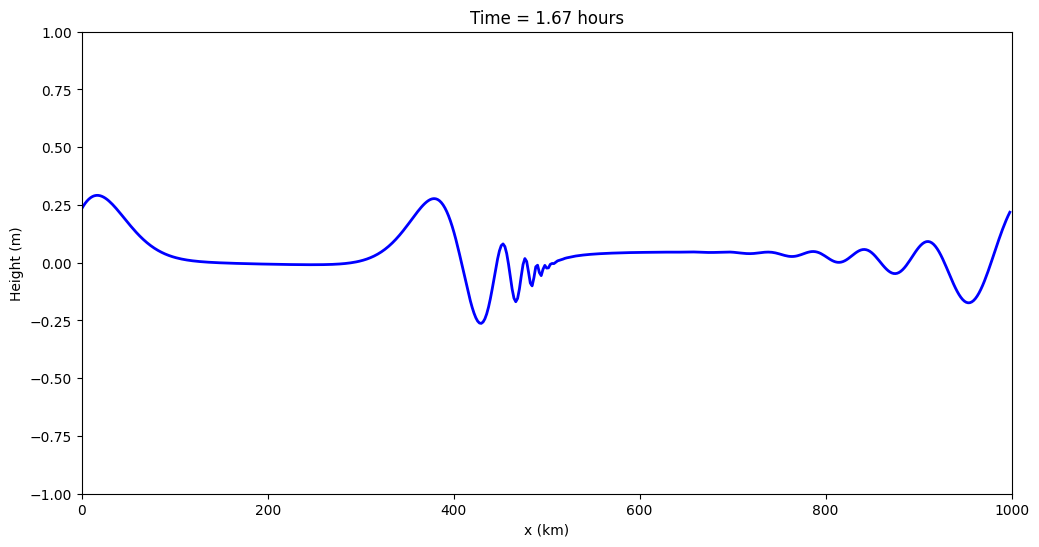

In [8]:
# create a figure and axes
fig = plt.figure(figsize=(12,6))

# Specify the axis limits and labels
plt.xlim((0, Lx / (1*kilometer)))
plt.ylim((-1, 1))
plt.xlabel('x (km)')
plt.ylabel('Height (m)')

H_x = H0 - (H0 - H_min) * np.exp(-(x - x2)**2.0 / w2**2.0)

# Create objects that will change during the animation
txt_title = plt.title('')
height, = plt.plot([], [], 'b', lw=2)

# Define an animation function
def drawframe(n):
    height.set_data(x/(1*kilometer), h_save[n,:])
    txt_title.set_text('Time = {0:.2f} hours'.format(t_save[n]/(1*hour)))
    return (height,)

from matplotlib import animation
# blit=True re-draws only the parts that have changed.
anim = animation.FuncAnimation(fig, drawframe, frames=len(t_save), interval=40, blit=True)

from IPython.display import HTML
HTML(anim.to_html5_video())


### 1.3 Student investigation
<a id='section1pt3'></a>
In the cells below, provide an expression for the expected wave speed and state any assumptions that are necessary to arrive at this. Then plot the wave speed from the output above and compare this with the expected value.

The expected wavespeed for a shallow water wave is:

$
c =  \sqrt{gH}=\sqrt{g(H_0-(H_0-H_{min})e^{\frac{-(x-x_2)^2}{w_{2}^2}}}
$

Assumptions:


*   The water depth $H$ is small compared to the width of the wave $w_1$.
*   The fluid is an incompressible fluid of constant density.
*   The system is in hydrostatic balance.
*   The perturbation in height, $h$ is small such that it can be linearised.



In [46]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Extract actual wave peak positions at each timestep with sub-grid interpolation
peak_positions = []
times = []

for i, t in enumerate(t_save):
    # Ignore the first 5 minutes to allow the initial wave to split cleanly
    # and avoid the overlapping-peak numerical artifact.
    if t < 0 * 60:
        continue
    # Track propagation up to 45 minutes to avoid boundary reflection issues
    if t > 60 * 60:
        break
    h_profile = h_save[i, :]

    # Search for the peak to the right of the initial perturbation (x > 200 km)
    search_idx = np.where(x > x1)[0]
    if len(search_idx) > 2:
        # Local grid index of maximum
        local_peak_idx = np.argmax(h_profile[search_idx])
        global_peak_idx = search_idx[local_peak_idx]

        # Perform quadratic sub-grid interpolation if not at the boundaries
        if 0 < local_peak_idx < len(search_idx) - 1:
            idx = global_peak_idx
            # Fit a parabola y = Ax^2 + Bx + C through three points
            x_pts = x[idx-1:idx+2]
            y_pts = h_profile[idx-1:idx+2]
            poly = np.polyfit(x_pts, y_pts, 2)
            # Peak is at -B / (2A)
            fine_peak_pos = -poly[1] / (2.0 * poly[0])
            peak_positions.append(fine_peak_pos)
        else:
            peak_positions.append(x[global_peak_idx])
        times.append(t)

peak_positions = np.array(peak_positions)
times = np.array(times)

# 2. Compute actual velocity at each timestep using central differences
# This ensures the velocity array has the exact same size as the time/position arrays.
actual_speed = np.zeros_like(peak_positions)

# Central difference for interior points
actual_speed[1:-1] = (peak_positions[2:] - peak_positions[:-2]) / (times[2:] - times[:-2])
# Forward/backward difference for boundaries
actual_speed[0] = (peak_positions[1] - peak_positions[0]) / (times[1] - times[0])
actual_speed[-1] = (peak_positions[-1] - peak_positions[-2]) / (times[-1] - times[-2])

# 3. Compute expected wave speed c(t) = sqrt(g * H(x(t))) at each timestep
H_tracked = H0 - (H0 - H_min) * np.exp(-(peak_positions - x2)**2.0 / w2**2.0)
c_expected = np.sqrt(g * H_tracked)

<>:11: SyntaxWarning: invalid escape sequence '\s'
<>:11: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_502/3546839257.py:11: SyntaxWarning: invalid escape sequence '\s'
  plt.plot(x_fine / kilometer, c_analytical, 'b-', label='Analytical Expected Speed $c(x) = \sqrt{g H(x)}$', lw=2.5)


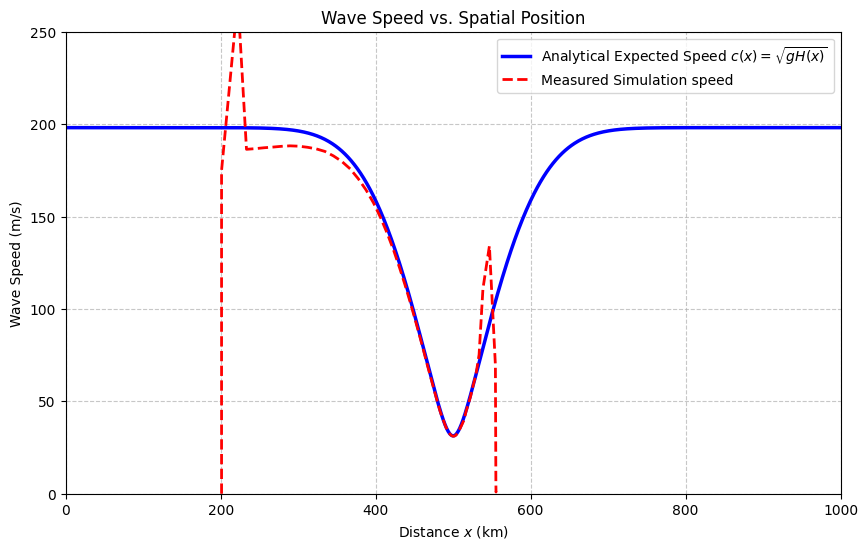

In [47]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate a continuous fine coordinate grid for the analytical curve
x_fine = np.linspace(0, Lx, 1000)
H_analytical = H0 - (H0 - H_min) * np.exp(-(x_fine - x2)**2.0 / w2**2.0)
c_analytical = np.sqrt(g * H_analytical)

# 2. Plot Wave Speed vs. Distance (x)
plt.figure(figsize=(10, 6))
plt.plot(x_fine / kilometer, c_analytical, 'b-', label='Analytical Expected Speed $c(x) = \sqrt{g H(x)}$', lw=2.5)
plt.plot(peak_positions / kilometer, abs(actual_speed), 'r--', label='Measured Simulation speed', lw=2)
plt.xlabel('Distance $x$ (km)')
plt.ylabel('Wave Speed (m/s)')
plt.title('Wave Speed vs. Spatial Position')
plt.xlim(0, Lx / kilometer)
plt.ylim(0,250)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()

The analytical expected speed of the wave peak is proportional to the square root of the surface depth, therefore decreases proportionally around the sea mount. The measured wave speed in the simulation starts from zero, as defined in the initial conditions, and then takes a few timesteps to reach a more steady simulated value as the initial wave splits in to two (right-moving and left-moving). The more steady simulated value is still less than expected between $x=250$ and $x=400$. This can be explained by the dispersion of the wave which results from the finite timesteps used in the simulation. After this, as the wave slows down towards the sea mount, the change in distance per timestep is reduced and so the error is reduced and the simulation becomes more accurate. Reducing the timestep would minimise both of these errors, as shown in the figure below where the timestep is reduced by a factor of 10. After the right-moving wave interacts with the sea mount, it meets the left-moving wave, and the peak-based wave speed tracker fails to identify the right-moving wave correctly and the simulation value deviates from the expected value again.

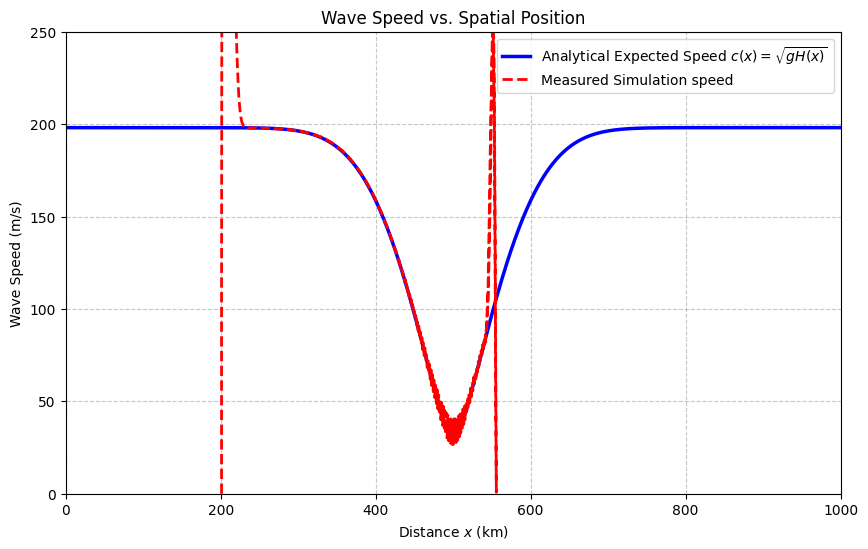

## 2.  2D Shallow water equations

Now, let's see how things change if we move to two dimensions. The script below solves the 2D shallow water equations:

$$ \partial_t u + g \partial_x(h) = - u*\partial_x u - v*\partial_y u$$
$$ \partial_t u + g \partial_y(h) = - u*\partial_x v - v*\partial_y v$$
$$ \partial_t h + H (\partial_x(u) + \partial_y(v)) = -\partial_x(h*u) - \partial_y(h*v)$$

We will solve these equations in a square domain with periodic boundary conditions. We will again initialize with a Gaussian height disturbance and with no water motion, but this time in 2D:

$$ h=e^{-(x^2+y^2)/w^2} $$
$$ u=0 $$
$$ v=0 $$

### 2.1  Dedalus script to solve the 2D shallow water equations

In [17]:
# Import the required packages
import numpy as np
import dedalus.public as dedalus
import logging
import matplotlib.pyplot as plt

logger = logging.getLogger(__name__)

# Define the simulation units. This is optional, but will help us keep track of units
meter = 1
kilometer = meter * 1e3
second = 1
minute = 60
hour = 3600
day = hour * 24

# Specify the simulation parameters
Lx = 1000 * kilometer # The domain size in x
Ly = 1000 * kilometer # The domain size in y
Nx = 64 # The number of gridpoints in x
Ny = 64 # The number of gridpoints in y
g = 9.81 * meter / second**2 # Gravitational acceleration
H = 4 * kilometer # Reference ocean depth
width = 100 * kilometer # Set the width of the initial Gaussian

timestep = 60 * second # Specify the timestep
stop_sim_time = 30 * minute # Specify the stopping time

timestepper = dedalus.RK222
max_timestep = 0.125

# Bases
coords = dedalus.CartesianCoordinates('x', 'y')
dist = dedalus.Distributor(coords, dtype=np.float64)
xbasis = dedalus.RealFourier(coords['x'], size=Nx, bounds=(-Lx/2, Lx/2), dealias=3/2)
ybasis = dedalus.RealFourier(coords['y'], size=Ny, bounds=(-Ly/2, Ly/2), dealias=3/2)

x, y = dist.local_grids(xbasis, ybasis)

# Fields
u = dist.Field(name='u', bases=(xbasis, ybasis))
v = dist.Field(name='v', bases=(xbasis, ybasis))
h = dist.Field(name='h', bases=(xbasis, ybasis))

# Initial conditions
h.change_scales(1) # Set values on regular grid
u.change_scales(1)
v.change_scales(1)
h['g'] = np.exp(-((x+ 150 * kilometer)**2+y**2)/width**2) + np.exp(-((x- 150 * kilometer)**2+y**2)/width**2)
# h['g'] = np.exp(-(10*x**2+y**2)/width**2)
# h['g'] = np.exp(-(x**2+y**2)/width**2)  # Initialize the dependent variable c with a Gaussian function (note ** is the exponentiation operator)
u['g'] = 0
v['g'] = 0

# Operators
dx = lambda a: dedalus.Differentiate(a, coords['x'])
dy = lambda a: dedalus.Differentiate(a, coords['y'])

# Problem
problem = dedalus.IVP([u, v, h], namespace=locals())
problem.add_equation("dt(u) + g*dx(h) = - u*dx(u) - v*dy(u)")
problem.add_equation("dt(v) + g*dy(h) = - u*dx(v) - v*dy(v)")
problem.add_equation("dt(h) + H*(dx(u) + dy(v)) = - dx(h*u) - dy(h*v)")

# Solver
solver = problem.build_solver(dedalus.RK222)
solver.stop_sim_time = stop_sim_time

# Analysis
snapshots = solver.evaluator.add_file_handler('snapshots', sim_dt=1*hour, max_writes=10)
snapshots.add_task(h, name='h')
snapshots.add_task(u, name='u')
snapshots.add_task(v, name='v')

h.change_scales(1)
h_save = [np.copy(h['g'])]; t_save = [solver.sim_time]; # Save the initial condition and the initial time
# Main loop
try:
    logger.info('Starting main loop')
    while solver.proceed:
        solver.step(timestep)
        if (solver.iteration-1) % 1 == 0:
            h.change_scales(1)
            h_save.append(np.copy(h['g']))
            t_save.append(solver.sim_time)
except:
    logger.error('Exception raised, triggering end of main loop.')
    raise
finally:
    solver.log_stats()

h_save=np.array(h_save) # convert h_save to an np.array type to allow data slicing

INFO:subsystems:Building subproblem matrices 1/32 (~3%) Elapsed: 0s, Remaining: 0s, Rate: 1.0e+02/s


2026-11-23 15:03:15,270 subsystems 0/1 INFO :: Building subproblem matrices 1/32 (~3%) Elapsed: 0s, Remaining: 0s, Rate: 1.0e+02/s


INFO:subsystems:Building subproblem matrices 4/32 (~12%) Elapsed: 0s, Remaining: 0s, Rate: 1.1e+02/s


2026-11-23 15:03:15,297 subsystems 0/1 INFO :: Building subproblem matrices 4/32 (~12%) Elapsed: 0s, Remaining: 0s, Rate: 1.1e+02/s


INFO:subsystems:Building subproblem matrices 8/32 (~25%) Elapsed: 0s, Remaining: 0s, Rate: 1.1e+02/s


2026-11-23 15:03:15,331 subsystems 0/1 INFO :: Building subproblem matrices 8/32 (~25%) Elapsed: 0s, Remaining: 0s, Rate: 1.1e+02/s


... (26 outputs left out)

INFO:solvers:CPU time (iter 10-end): 4.27e-05 cpu-hr


2026-11-23 15:03:15,806 solvers 0/1 INFO :: CPU time (iter 10-end): 4.27e-05 cpu-hr


INFO:solvers:Speed: 3.098e+06 mode-stages/cpu-sec


2026-11-23 15:03:15,808 solvers 0/1 INFO :: Speed: 3.098e+06 mode-stages/cpu-sec


### 2.2  Plotting
The code below will make a movie of the height as a function of x and y

INFO:matplotlib.animation:Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


2026-11-23 15:03:19,322 matplotlib.animation 0/1 INFO :: Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


INFO:matplotlib.animation:MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 600x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmpdvsm3l78/temp.m4v


2026-11-23 15:03:19,325 matplotlib.animation 0/1 INFO :: MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 600x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmpdvsm3l78/temp.m4v


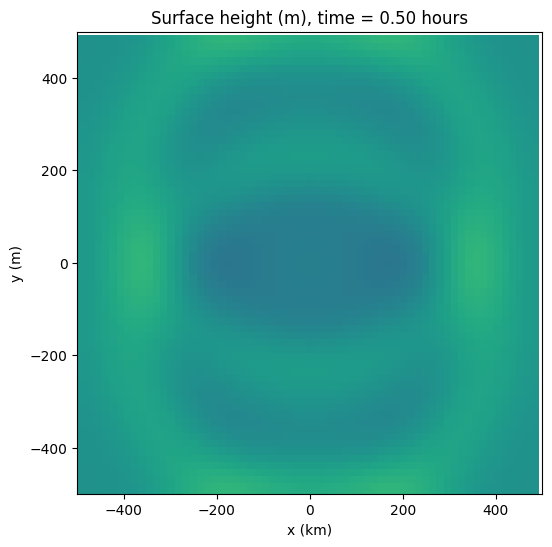

In [18]:
# create a figure and axes
fig = plt.figure(figsize=(6,6))

# Create arrays with the x and y coordinates for plotting using pcolor
from dedalus.extras import plot_tools
(X, Y) = plot_tools.quad_mesh(np.squeeze(x), np.squeeze(y))

# Define an animation function
def drawframe(n):
    plt.clf # clear the figure before plotting the next frame
    height = plt.pcolor(X/(1*kilometer), Y/(1*kilometer), h_save[n,:,:], vmin=-1, vmax=1)
    # Specify the axis limits and labels
    plt.xlim((-Lx/2 / (1*kilometer),Lx/2 / (1*kilometer)))
    plt.ylim((-Ly/2 / (1*kilometer),Ly/2 / (1*kilometer)))
    plt.xlabel('x (km)')
    plt.ylabel('y (m)')
    plt.title('Surface height (m), time = {0:.2f} hours'.format(t_save[n]/(1*hour)))
    return (height,)

from matplotlib import animation
# blit=True re-draws only the parts that have changed.
anim = animation.FuncAnimation(fig, drawframe, frames=len(t_save), interval=40, blit=True)

from IPython.display import HTML
HTML(anim.to_html5_video())

### 2.3 Student investigation
<a id='section2pt3'></a>
Notice how the amplitude of the Tsunami wave decreases with distance from the source location. In the cell below, make a prediction for how the wave amplitude will vary as a function of distance from the origin (x=0, y=0) using conservation of energy. Then, make a plot or plots comparing your prediction for the wave amplitude compared with the results from the simulation.

Try out several different possible initial conditions for the surface height, $h$. How does the shape of the resulting waves change?

The wave amplitude $h$ will vary inversely proportional to the square root of the distance from the origin, which if we assume the wave propagates radially we can call that distance $r$.

$h \propto \frac{1}{\sqrt{r}}$

This is determined from a scaling analysis of the combined kinetic and potential energy equations, which is

$E =\int \int (\frac{1}{2}\rho g h^2 + \frac{1}{2}\rho H |\textbf{u}|^2)dA = \int \int h^2 \rho g\space dA =$ const.

as energy must be conserved. In polar coordinates, $dA = rdrd\theta$, so considering the wave expanding as a ring of constant width $w$ and radius $r$, we get $E\sim ρgh^2 2 \pi r w$ which yields the scaling for $h$ as above.

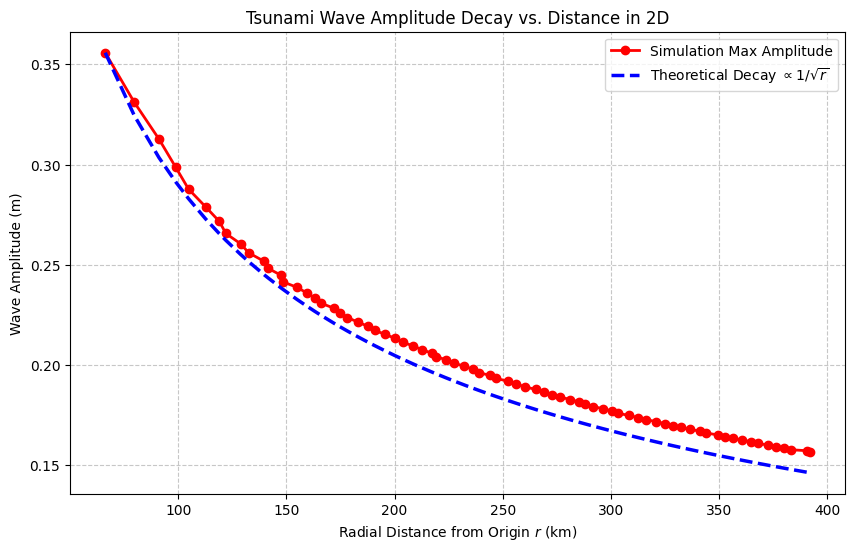

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Coordinate Setup (same as 2D simulation)
# Lx, Ly and x, y are defined in the 2D script
# h_save has shape (time, Ny, Nx) or (time, Nx, Ny)
# Let's verify coordinates from the 2D simulation
x_1d = np.squeeze(x[:, 0])
y_1d = np.squeeze(y[0, :])

# Calculate radial distance r from the center (0,0) for each grid point
X_grid, Y_grid = np.meshgrid(x_1d, y_1d, indexing='ij')
R_grid = np.sqrt(X_grid**2 + Y_grid**2) / (1*kilometer)

# 2. Track the peak amplitude of the propagating wave packet as a function of radius
# For each timestep, find the maximum height 'h' and its corresponding radial distance.
# To avoid the initial non-split wave and boundary reflections, we focus on the propagation phase.
radii = []
amplitudes = []

# Start after a few timesteps so the wave has cleanly formed and split
for n in range(17, len(t_save)):
    h_frame = h_save[n, :, :]
    # Find where the wave peak is located (excluding the very center to track the propagating ring)
    mask = (R_grid > 0) & (R_grid < 450)
    if np.any(mask):
        max_val = np.max(h_frame[mask])
        max_idx = np.unravel_index(np.argmax(h_frame * mask), h_frame.shape)
        r_peak = R_grid[max_idx]
        radii.append(r_peak)
        amplitudes.append(max_val)

radii = np.array(radii)
amplitudes = np.array(amplitudes)

# 3. Fit a 1/sqrt(r) reference decay curve
# We normalize the reference curve to match the first tracked clean propagating point
ref_decay = amplitudes[0] * np.sqrt(radii[0]) / np.sqrt(radii)

# 4. Plot the comparison
plt.figure(figsize=(10, 6))
plt.plot(radii, amplitudes, 'ro-', label='Simulation Max Amplitude', lw=2)
plt.plot(radii, ref_decay, 'b--', label=r'Theoretical Decay $\propto 1/\sqrt{r}$', lw=2.5)
plt.xlabel('Radial Distance from Origin $r$ (km)')
plt.ylabel('Wave Amplitude (m)')
plt.title('Tsunami Wave Amplitude Decay vs. Distance in 2D')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()

One change to the initial conditions was making the source elliptical by stretching it in either the $x$ or $y$ direction, e.g.

$h(x, y) = e^{-(10x^2 + y^2) / w^2}$

This simulates a tsunami formed from an earthquake along a faultline. It causes the wave to propagate more strongly in the $y$-direction as two horizontal beams, instead of radially.

Another change was to add a second source and observe how the waves interact, e.g.

$h(x, y) = e^{-\left((x - d)^2 + y^2\right) / w^2} + e^{-\left((x + d)^2 + y^2\right) / w^2}$

where the two sources are $2d$. This results in constructive and destructive interference, where the waves are more amplified in some regions, but they still propagate radially.

## 3. Shallow water equations on a sphere

Of course the Earth isn't a flat plane. A great strength of Dedalus is its flexibility to solve equations in various geometries. The script below solves the 2D shallow water equations on a spherical shell, where the azimuth and colatitude are the independent variables. The colatitude is the complementary angle to the latitude such that the colatitude is $0^\circ$ at the North Pole, $90^\circ$ at the Equator, and $180^\circ$ at the South Pole. The spherical geometry also allows us to take into account the Earth's rotation in a realistic way.

Specifically, we will solve the following equations:
$$ \partial_t \mathbf{u} + g \nabla h + 2 \Omega \hat{\mathbf{z}} \times \mathbf{u} = -\mathbf{u} \cdot \nabla \mathbf{u} $$
$$ \partial_t + H \nabla \cdot \mathbf{u} = -\nabla \cdot (h \mathbf{u}) $$

where $\mathbf{u}$ is the velocity vector, $\Omega$ is the Earth's angular velocity (in radians per second), and $\hat{\mathbf{z}}$ is a unit vector aligned with the North Pole. Note that we have written the equations above in vector form. Dedalus includes vector calculus operators that make it very natural to solve equations like this without worrying about the particular form of the vector operators in a curvilinear coordinate system.

### 3.1  Dedalus script for 2D shallow water equations on a sphere

In [19]:
# Import the required packages
import numpy as np
import dedalus.public as dedalus
import logging
import matplotlib.pyplot as plt

logger = logging.getLogger(__name__)

# Define the simulation units. This is optional, but will help us keep track of units
meter = 1
kilometer = meter * 1e3
second = 1
minute = 60
hour = 3600
day = hour * 24

# Parameters
Nphi = 128 # Number of gridpoints in phi (longitude)
Ntheta = 64 # Number of gridpoints in theta (colatitude)
R = 6.37122e3 * kilometer
Omega = 2 * np.pi / (1 * day) # Earth's angular velocity in radians per second
g = 9.80616 * meter / second**2 # Gravitational acceleration
H = 4 * kilometer # Depth of the ocean
width = 2*np.pi*10/360 # Width of the initial Gaussian in radians
phi0 = np.pi # Longitude of the initial Gaussian height perturbation in radians
theta0 = np.pi/4 # Colatitude of the initial Gaussian height perturbation in radians

timestep = 600 * second
stop_sim_time = 10 * day

# Bases
coords = dedalus.S2Coordinates('phi', 'theta')
dist = dedalus.Distributor(coords, dtype=np.float64)
basis = dedalus.SphereBasis(coords, (Nphi, Ntheta), radius=R, dealias=3/2, dtype=np.float64)

# Define the coordinates
phi, theta = dist.local_grids(basis) # Longitude and colatitude
lat = 360*(np.pi / 2 - theta)/(2*np.pi)  # latitude in degrees

# Fields
u = dist.VectorField(coords, name='u', bases=basis)
h = dist.Field(name='h', bases=basis)

# Operators
# First, create an operator to perform the cross product: "z x ", where z is the local vertical unit vector
# The "skew" operator performs a 90 degree rotation of a vector field,
# so that skew([u,v]) = [-v, u].  MulCosine multiplies by the cosine of the latitude
zcross = lambda A: dedalus.MulCosine(dedalus.skew(A))

# Set the initial conditions
h.change_scales(1) # Set values on regular grid
u.change_scales(1)
h['g'] = np.exp(-((phi-phi0)**2+(theta-theta0)**2)/width**2)  # Initialize the dependent variable c with a Gaussian function (note ** is the exponentiation operator)
# Set the initial velocity to zero
u['g'][0] = 0 # the x-component of the velocity
u['g'][1] = 0 # the y-component of the velocity

# Problem
problem = dedalus.IVP([u, h], namespace=locals())
problem.add_equation("dt(u) + g*grad(h) + 2*Omega*zcross(u) = - u@grad(u)")
problem.add_equation("dt(h) + H*div(u) = - div(h*u)")

# Solver
solver = problem.build_solver(dedalus.RK222)
solver.stop_sim_time = stop_sim_time

h.change_scales(1)
h_save = [np.copy(h['g'])]; t_save = [solver.sim_time]; # Save the initial condition and the initial time
# Main loop
try:
    logger.info('Starting main loop')
    while solver.proceed:
        solver.step(timestep)
        if (solver.iteration-1) % 1 == 0:
            logger.info('Iteration=%i, Time=%e, dt=%e' %(solver.iteration, solver.sim_time, timestep))
            h.change_scales(1)
            h_save.append(np.copy(h['g']))
            t_save.append(solver.sim_time)
except:
    logger.error('Exception raised, triggering end of main loop.')
    raise
finally:
    solver.log_stats()

h_save = np.array(h_save)

INFO:subsystems:Building subproblem matrices 1/63 (~2%) Elapsed: 0s, Remaining: 2s, Rate: 2.8e+01/s


2026-11-23 16:30:10,194 subsystems 0/1 INFO :: Building subproblem matrices 1/63 (~2%) Elapsed: 0s, Remaining: 2s, Rate: 2.8e+01/s


INFO:subsystems:Building subproblem matrices 7/63 (~11%) Elapsed: 0s, Remaining: 1s, Rate: 4.8e+01/s


2026-11-23 16:30:10,306 subsystems 0/1 INFO :: Building subproblem matrices 7/63 (~11%) Elapsed: 0s, Remaining: 1s, Rate: 4.8e+01/s


INFO:subsystems:Building subproblem matrices 14/63 (~22%) Elapsed: 0s, Remaining: 1s, Rate: 4.5e+01/s


2026-11-23 16:30:10,471 subsystems 0/1 INFO :: Building subproblem matrices 14/63 (~22%) Elapsed: 0s, Remaining: 1s, Rate: 4.5e+01/s


... (2,908 outputs left out)

INFO:solvers:CPU time (iter 10-end): 0.02714 cpu-hr


2026-11-23 16:31:54,441 solvers 0/1 INFO :: CPU time (iter 10-end): 0.02714 cpu-hr


INFO:solvers:Speed: 3.54e+05 mode-stages/cpu-sec


2026-11-23 16:31:54,443 solvers 0/1 INFO :: Speed: 3.54e+05 mode-stages/cpu-sec


### 3.2  Plotting
The code below will make a movie of the height as a function of x and y

INFO:matplotlib.animation:Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


2026-11-19 16:12:29,808 matplotlib.animation 0/1 INFO :: Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


INFO:matplotlib.animation:MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmpf0c5z910/temp.m4v


2026-11-19 16:12:29,810 matplotlib.animation 0/1 INFO :: MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmpf0c5z910/temp.m4v


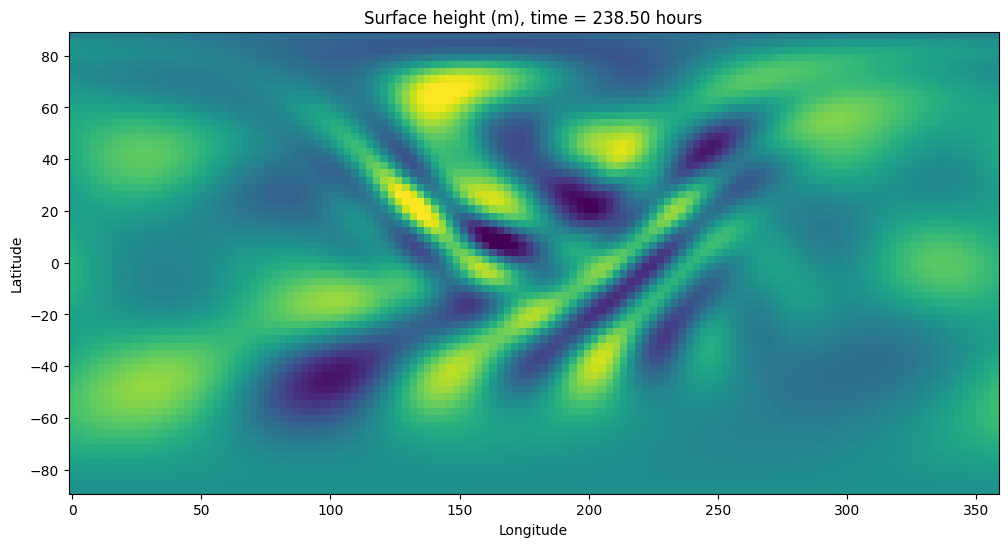

In [29]:
# create a figure and axes
fig = plt.figure(figsize=(12,6))

# Create arrays with the latitude and longitude coordinates for plotting using pcolor
from dedalus.extras import plot_tools
(X, Y) = plot_tools.quad_mesh(np.squeeze(np.pi/2 - theta)*360/2/np.pi, np.squeeze(phi)*360/2/np.pi)

# Define an animation function
def drawframe(n):
    plt.clf()
    height = plt.pcolor(Y, X, h_save[n,:,:], vmin=-0.1, vmax=0.1)
    # Specify the axis limits and labels
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.title('Surface height (m), time = {0:.2f} hours'.format(t_save[n]/(1*hour)))
    return (height,)

from matplotlib import animation
# blit=True re-draws only the parts that have changed.
anim = animation.FuncAnimation(fig, drawframe, frames=len(t_save), interval=40, blit=True)

from IPython.display import HTML
HTML(anim.to_html5_video())

### 3.3 Student investigation
<a id='section3pt3'></a>
Create a virtual tide gauge by sampling the height at a point at a latitude of 45ºN and longitude of 90ºW and plot the timeseries of the height at this point in the cells below. You should modify the code to save the height more often so that you can clearly see the shape of the wave. Notice that as the waves propagate around the Earth, their shape changes. Discuss physical mechanisms that might cause the shape of the wave to change as the wave propagates.

The waves undergo some initial dispersion as they split from the initial Gaussian as they expand radially and the wave energy spreads. This leaves a trail after the front moving wave which can be seen after the first peak on the tide gauge between days 0 and 2.

The wave shape is also changed by the coriolis force, which causes the wave to shift varying amounts dependant on latitude, and in opposite directions dependant on the hemisphere. This leads to asymmetric waves, which then cause varying levels of interference when they meet waves coming the other direction on the sphere, which can be seen on the tide gauge at later times.

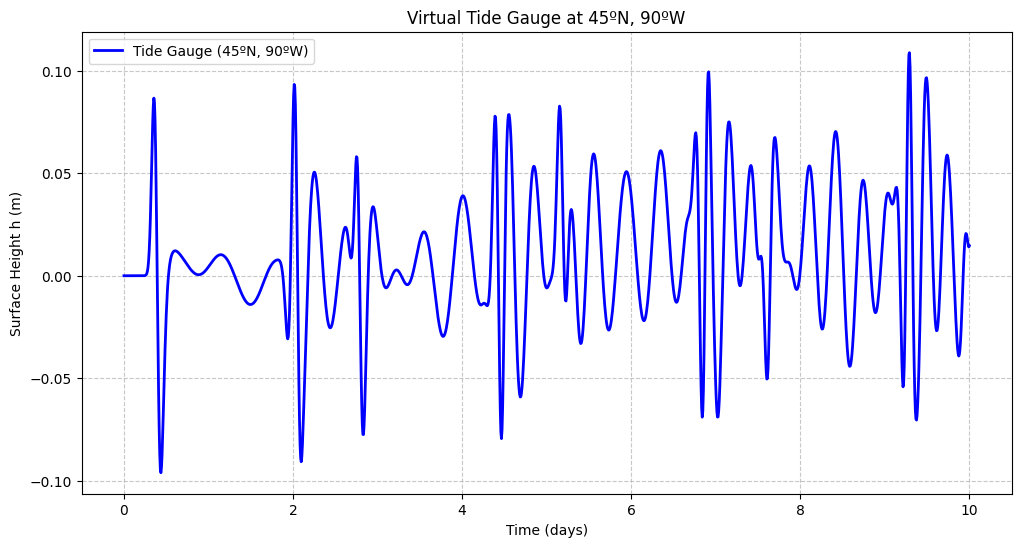

In [38]:
import numpy as np
import matplotlib.pyplot as plt

# Target coordinates: 45ºN latitude -> colatitude = pi/4 radians
# 90ºW longitude -> phi = 3*pi/2 radians
target_theta = np.pi / 4
target_phi = 3 * np.pi / 2

# Safely extract 1D coordinates
theta_1d = np.squeeze(theta)
phi_1d = np.squeeze(phi)

# Find the index of the grid points closest to our target coordinates
theta_idx = np.argmin(np.abs(theta_1d - target_theta))
phi_idx = np.argmin(np.abs(phi_1d - target_phi))

# Extract height timeseries at this virtual tide gauge location
# h_save shape: (time, phi, theta)
tide_gauge_heights = h_save[:, phi_idx, theta_idx]
t_days = np.array(t_save) / day

# Plot the virtual tide gauge timeseries
plt.figure(figsize=(12, 6))
plt.plot(t_days, tide_gauge_heights, 'b-', lw=2, label='Tide Gauge (45ºN, 90ºW)')
plt.xlabel('Time (days)')
plt.ylabel('Surface Height h (m)')
plt.title('Virtual Tide Gauge at 45ºN, 90ºW')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()

In the simulation above, the Tsunami wave travels around the planet many times. In reality, the waves will partially dissipate when they reach shorelines. In the spherical shallow water equation code above (or in a new code block below), add a forcing term to the shallow water equations that damps the waves for longitudes larger than $\pm 90^\circ$. Specifically, add a forcing function to the right hand side of the height equation of the following form:

$$ - (1/\tau) f(\phi) h$$

where

$$ f(\phi) = \frac{1}{2}\left(1+tanh\left(\frac{\phi-3\pi/2}{\pi/10}\right)\right) + \frac{1}{2}\left(1-tanh\left(\frac{\phi-\pi/2}{\pi/10}\right)\right) $$

and $\phi$ is the co-latitude in radians and $\tau$ is a damping timescale. A timescale of $\tau=0.1$ days should be sufficient to damp the waves.

With this damping term active, much more slowly propagating waves should be visible. These are shallow water Rossby waves. Estimate the east/west phase speed of these Rossby waves and compare them with the phase speed that you can infer from the simulation by plotting the height, $h$, as a function of longitude and time. Discuss the spatial structure of the Rossby waves and any discrepancies that you see between your estimated and measured phase speeds.

In [24]:
# Import the required packages
import numpy as np
import dedalus.public as dedalus
import logging
import matplotlib.pyplot as plt

logger = logging.getLogger(__name__)

# Define the simulation units
meter = 1
kilometer = meter * 1e3
second = 1
minute = 60
hour = 3600
day = hour * 24

# Parameters
Nphi = 128 # Number of gridpoints in phi (longitude)
Ntheta = 64 # Number of gridpoints in theta (colatitude)
R = 6.37122e3 * kilometer
Omega = 2 * np.pi / (1 * day) # Earth's angular velocity
g = 9.80616 * meter / second**2 # Gravitational acceleration
H = 4 * kilometer # Depth of the ocean
width = 2*np.pi*10/360 # Width of the initial Gaussian in radians
phi0 = np.pi
theta0 = np.pi/4

timestep = 600 * second
stop_sim_time = 10 * day

# Bases
coords = dedalus.S2Coordinates('phi', 'theta')
dist = dedalus.Distributor(coords, dtype=np.float64)
basis = dedalus.SphereBasis(coords, (Nphi, Ntheta), radius=R, dealias=3/2, dtype=np.float64)

# Define the coordinates
phi, theta = dist.local_grids(basis)

# Fields
u = dist.VectorField(coords, name='u', bases=basis)
h = dist.Field(name='h', bases=basis)

# Operators & Damping Profile
zcross = lambda A: dedalus.MulCosine(dedalus.skew(A))

# Damping parameters: tau = 0.1 days
tau = 0.1 * day

# Define spatial damping field
f_phi = dist.Field(name='f_phi', bases=basis)
f_phi.change_scales(1)
f_phi['g'] = 0.5 * (1 + np.tanh((phi - 3*np.pi/2) / (np.pi / 10))) + 0.5 * (1 - np.tanh((phi - np.pi/2) / (np.pi / 10)))

# Set the initial conditions
h.change_scales(1)
u.change_scales(1)
h['g'] = np.exp(-((phi-phi0)**2+(theta-theta0)**2)/width**2)
u['g'][0] = 0
u['g'][1] = 0

# Problem
# Note: Variable coefficient term (1/tau)*f_phi*h has been moved to the RHS
problem = dedalus.IVP([u, h], namespace=locals())
problem.add_equation("dt(u) + g*grad(h) + 2*Omega*zcross(u) = - u@grad(u)")
problem.add_equation("dt(h) + H*div(u) = - div(h*u) - (1/tau)*f_phi*h")

# Solver
solver = problem.build_solver(dedalus.RK222)
solver.stop_sim_time = stop_sim_time

h.change_scales(1)
h_save_damped = [np.copy(h['g'])]
t_save_damped = [solver.sim_time]

# Main loop
try:
    logger.info('Starting main loop with wave damping')
    while solver.proceed:
        solver.step(timestep)
        if (solver.iteration-1) % 1 == 0:
            h.change_scales(1)
            h_save_damped.append(np.copy(h['g']))
            t_save_damped.append(solver.sim_time)
except:
    logger.error('Exception raised, triggering end of main loop.')
    raise
finally:
    solver.log_stats()

h_save_damped = np.array(h_save_damped)
t_save_damped = np.array(t_save_damped)

INFO:subsystems:Building subproblem matrices 1/63 (~2%) Elapsed: 0s, Remaining: 1s, Rate: 7.4e+01/s


2026-11-23 18:07:20,254 subsystems 0/1 INFO :: Building subproblem matrices 1/63 (~2%) Elapsed: 0s, Remaining: 1s, Rate: 7.4e+01/s


INFO:subsystems:Building subproblem matrices 7/63 (~11%) Elapsed: 0s, Remaining: 1s, Rate: 9.2e+01/s


2026-11-23 18:07:20,317 subsystems 0/1 INFO :: Building subproblem matrices 7/63 (~11%) Elapsed: 0s, Remaining: 1s, Rate: 9.2e+01/s


INFO:subsystems:Building subproblem matrices 14/63 (~22%) Elapsed: 0s, Remaining: 1s, Rate: 9.2e+01/s


2026-11-23 18:07:20,393 subsystems 0/1 INFO :: Building subproblem matrices 14/63 (~22%) Elapsed: 0s, Remaining: 1s, Rate: 9.2e+01/s


... (28 outputs left out)

INFO:solvers:CPU time (iter 10-end): 0.02188 cpu-hr


2026-11-23 18:08:43,661 solvers 0/1 INFO :: CPU time (iter 10-end): 0.02188 cpu-hr


INFO:solvers:Speed: 4.39e+05 mode-stages/cpu-sec


2026-11-23 18:08:43,662 solvers 0/1 INFO :: Speed: 4.39e+05 mode-stages/cpu-sec


INFO:matplotlib.animation:Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


2026-11-22 14:58:55,298 matplotlib.animation 0/1 INFO :: Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


INFO:matplotlib.animation:MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmpayi64z7a/temp.m4v


2026-11-22 14:58:55,302 matplotlib.animation 0/1 INFO :: MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmpayi64z7a/temp.m4v


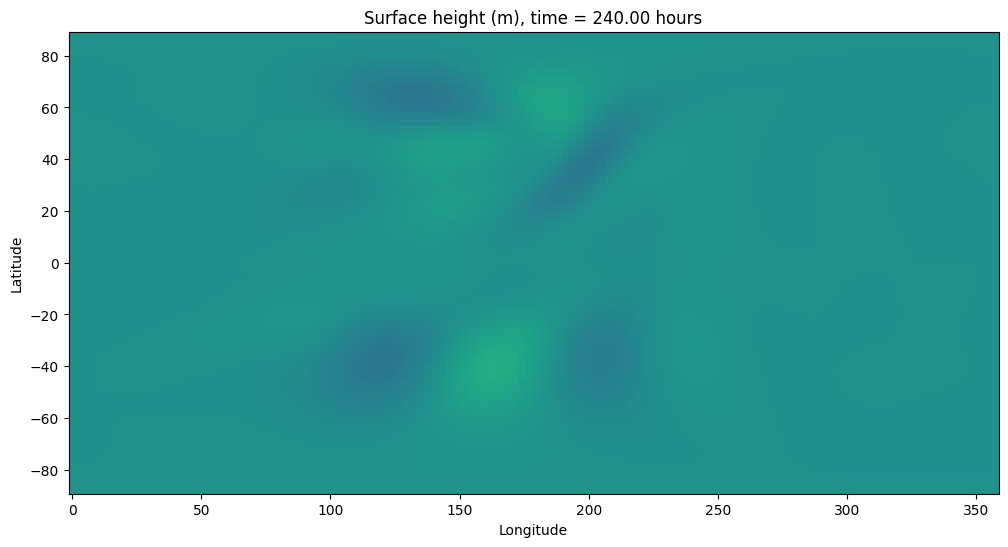

In [3]:
# create a figure and axes
fig = plt.figure(figsize=(12,6))

# Create arrays with the latitude and longitude coordinates for plotting using pcolor
from dedalus.extras import plot_tools
(X, Y) = plot_tools.quad_mesh(np.squeeze(np.pi/2 - theta)*360/2/np.pi, np.squeeze(phi)*360/2/np.pi)

# Define an animation function
def drawframe(n):
    plt.clf()
    height = plt.pcolor(Y, X, h_save_damped[n,:,:], vmin=-0.1, vmax=0.1)
    # Specify the axis limits and labels
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.title('Surface height (m), time = {0:.2f} hours'.format(t_save_damped[n]/(1*hour)))
    return (height,)

from matplotlib import animation
# blit=True re-draws only the parts that have changed.
anim = animation.FuncAnimation(fig, drawframe, frames=len(t_save_damped), interval=40, blit=True)

from IPython.display import HTML
HTML(anim.to_html5_video())

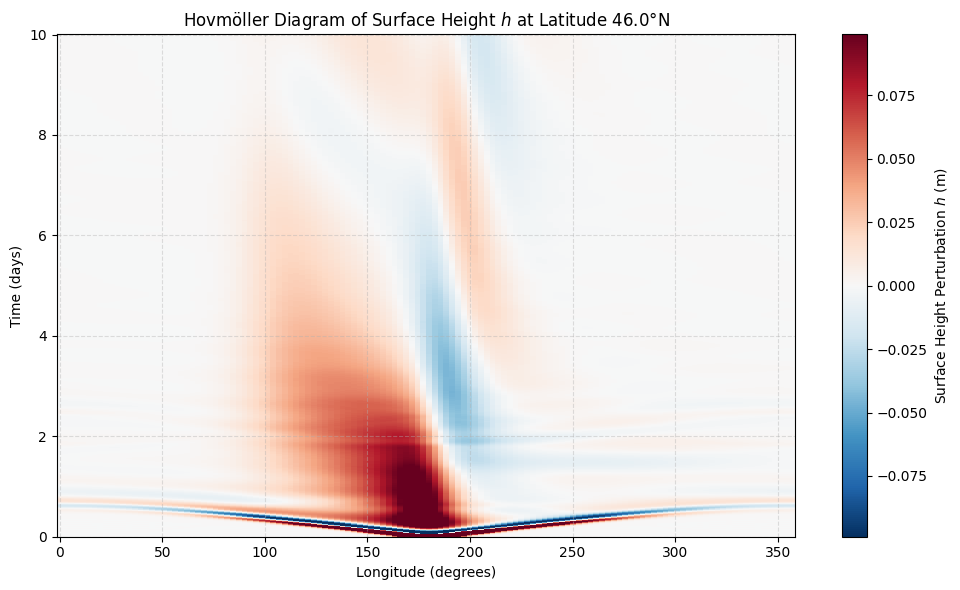

In [29]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Extract 1D coordinate arrays from the spherical simulation
phi_1d = np.squeeze(phi)                        # Longitude in radians [0, 2*pi)
lon_deg = np.degrees(phi_1d)                    # Convert longitude to degrees [0, 360)
lat_1d = np.squeeze(lat)                        # Latitude in degrees
times_days = np.array(t_save_damped) / day             # Time array in days

# 2. Choose a target latitude slice (e.g., 45°N where the initial perturbation is centered)
target_lat = 45.0
lat_idx = np.argmin(np.abs(lat_1d - target_lat))
actual_lat = lat_1d[lat_idx]

# 3. Slice h_save along that latitude: shape (n_times, Nphi)
# Note: in Dedalus S2Coordinates('phi', 'theta'), h_save has shape (time, Nphi, Ntheta)
h_hovmoller = h_save_damped[:, :, lat_idx]

# 4. Plot h as a function of longitude and time
fig, ax = plt.subplots(figsize=(10, 6))

# Use symmetric color limits around 0 so westward/eastward phase propagation stands out clearly
vmax = np.max(np.abs(h_hovmoller)) * 0.1
pcm = ax.pcolormesh(
    lon_deg,
    times_days,
    h_hovmoller,
    shading='auto',
    cmap='RdBu_r',
    vmin=-vmax,
    vmax=vmax
)

cbar = plt.colorbar(pcm, ax=ax, label='Surface Height Perturbation $h$ (m)')
ax.set_xlabel('Longitude (degrees)')
ax.set_ylabel('Time (days)')
ax.set_title(f'Hovmöller Diagram of Surface Height $h$ at Latitude {actual_lat:.1f}°N')
ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

## 4. Optional further investigations

* In the example of the shallow water equations on a sphere, introduce bathymetry by making $H$ a function of latitude and longitude. Make sure that you modify the equations in Dedalus appropriately. How do the waves behave when they encounter shallow water (e.g. a localized seamount)?

* It is quite difficult to simulate changing sea level (sometimes called wetting and drying), which is why the examples above do not include land. However, we can estimate the distance that a Tsunami will propagate using physical and dimensional arguments. Consider, for example, a flat, sloping beach. In the absence of energy dissipation, estimate the distance that a wave will propagate onshore. How could you modify this estimate to include energy dissipation (or drag)?